# SCED Results — IEEE 9-Bus

Scenarios are defined in `scenarios.yaml`. Change `SCENARIO` in the next cell to switch.
Each scenario specifies generators, loads, diurnal profile, and optional line capacity overrides.

In [ ]:
import sys, os, importlib, yaml
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure testbed modules are importable
testbed_dir = os.path.abspath('.')
repo_root = os.path.abspath('..')
for p in [testbed_dir, repo_root]:
    if p not in sys.path:
        sys.path.insert(0, p)

from ieee9_network import build_ieee9_network
from clearing.sced_clearing import clear_sced

import nodal_plot
importlib.reload(nodal_plot)
from nodal_plot import (
    plot_nodal_circlize, plot_network_topology,
    assign_bus_colors, compute_ptdf_flows,
    BUS_PALETTE, TRANSIT_COLOR, _darken,
)

# ---------- CHANGE THIS TO SWITCH SCENARIOS ----------
SCENARIO = "congested"
PLOT_HOUR = 12
# ------------------------------------------------------

# Load scenario config
with open('scenarios.yaml') as f:
    all_scenarios = yaml.safe_load(f)

assert SCENARIO in all_scenarios, f"Unknown scenario '{SCENARIO}'. Available: {list(all_scenarios.keys())}"
cfg = all_scenarios[SCENARIO]
scenario_name = cfg['name']
print(f'Scenario: {scenario_name}')
print(f'Plot hour: {PLOT_HOUR}')

Scenario: Congested (Lines 4-5, 7-8 at 90 MW)
Plot hour: 12


## Build Network & Run SCED

In [ ]:
# Build IEEE 9-bus network
periods = cfg.get('periods', 24)
network = build_ieee9_network(periods=periods)

# Apply line overrides from scenario
for line_name, overrides in cfg.get('line_overrides', {}).items():
    for col, val in overrides.items():
        network.lines.loc[line_name, col] = val
        print(f'  Override: line {line_name} {col} = {val}')

# Extract grid_data for the adapter
grid_data = {
    'buses': network.buses[['v_nom']].copy(),
    'lines': network.lines[['bus0', 'bus1', 's_nom', 'x_pu_eff', 'r_pu_eff']].copy(),
}

# Build market products
start_time = network.snapshots[0].to_pydatetime()
market_products = []
for i in range(periods):
    t_start = start_time + timedelta(hours=i)
    t_end = t_start + timedelta(hours=1)
    market_products.append((t_start, t_end, None))

# Build diurnal load profile from config
prof = cfg.get('profile', {})
hours = np.arange(periods) % 24
if prof.get('type') == 'diurnal':
    profile = np.clip(
        prof['base'] + prof['amplitude'] * np.sin(np.pi * (hours - prof['phase_shift']) / prof['period']),
        prof['clip_min'], prof['clip_max']
    )
else:
    profile = np.ones(periods)

# Build orderbook from scenario config
gen_data = cfg['generators']
load_data = cfg['loads']

orderbook = []
for gen_name, gd in gen_data.items():
    for i, (t_start, t_end, _) in enumerate(market_products):
        orderbook.append({
            'bid_id': f'{gen_name}_{i}', 'start_time': t_start, 'end_time': t_end,
            'volume': gd['p_max'], 'accepted_volume': 0.0,
            'price': gd['price'], 'accepted_price': 0.0,
            'agent_addr': f'agent_{gen_name}', 'unit_id': gen_name,
            'node': gd['bus'], 'only_hours': None,
        })
for load_name, ld in load_data.items():
    for i, (t_start, t_end, _) in enumerate(market_products):
        orderbook.append({
            'bid_id': f'{load_name}_{i}', 'start_time': t_start, 'end_time': t_end,
            'volume': -ld['p_base'] * profile[i], 'accepted_volume': 0.0,
            'price': 1000.0, 'accepted_price': 0.0,
            'agent_addr': f'agent_{load_name}', 'unit_id': load_name,
            'node': ld['bus'], 'only_hours': None,
        })

print(f'Grid: {len(grid_data["buses"])} buses, {len(grid_data["lines"])} lines')
print(f'Orders: {len(orderbook)} ({sum(1 for o in orderbook if o["volume"] > 0)} supply, '
      f'{sum(1 for o in orderbook if o["volume"] < 0)} demand)')

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
  Override: line line_1 s_nom = 90.0
  Override: line line_5 s_nom = 90.0
Grid: 9 buses, 9 lines
Orders: 168 (96 supply, 72 demand)


In [ ]:
# Run SCED
accepted, rejected, meta, flows = clear_sced(
    orderbook=orderbook,
    market_products=market_products,
    grid_data=grid_data,
    solver='highs',
)

print(f'Accepted: {len(accepted)}, Rejected: {len(rejected)}')
print(f'Meta entries: {len(meta)}, Flow entries: {len(flows)}')

INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 1118 rows; 1032 cols; 2080 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 6e+03]
  Cost    [1e+00, 1e+08]
  Bound   [5e-01, 3e+00]
  RHS     [5e-01, 3e+00]
Presolving model
24 rows, 240 cols, 240 nonzeros  0s
24 rows, 144 cols, 144 nonzeros  0s
Dependent equations search running on 24 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
24 rows, 144 cols, 144 nonzeros  0s
Presolve reductions: rows 24(-1094); columns 144(-888); nonzeros 144(-1936) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 24(56.0864) 0.0s
         24     1.1911324139e+05 Pr: 0(0) 0.0s

Performed postsolve
Sol

In [ ]:
# Convert to DataFrames for easier manipulation
acc_df = pd.DataFrame(accepted)
meta_df = pd.DataFrame(meta)

# Build per-bus, per-hour LMP table from accepted orders
# (each accepted order has accepted_price = LMP at its bus)
lmp_records = []
for o in accepted:
    lmp_records.append({
        'hour': o['start_time'].hour,
        'start_time': o['start_time'],
        'bus': o['node'],
        'lmp': o['accepted_price'],
    })
lmp_df = pd.DataFrame(lmp_records).drop_duplicates(subset=['hour', 'bus'])

# Pivot: rows=hour, columns=bus
lmp_pivot = lmp_df.pivot(index='hour', columns='bus', values='lmp').sort_index()
print('LMP table ($/MWh by bus and hour):')
lmp_pivot

LMP table ($/MWh by bus and hour):


bus,1,2,3,5,7,9
hour,,,,,,
0,20.0,NaN,NaN,20.000000,20.000000,20.000000
1,20.0,NaN,NaN,20.000000,20.000000,20.000000
2,20.0,NaN,NaN,20.000000,20.000000,20.000000
3,20.0,NaN,NaN,20.000000,20.000000,20.000000
4,20.0,NaN,NaN,20.000000,20.000000,20.000000
5,20.0,35.0,NaN,55.902439,39.390244,25.182927
6,20.0,35.0,NaN,55.902439,39.390244,25.182927
7,20.0,35.0,NaN,55.902439,39.390244,25.182927
8,20.0,35.0,NaN,55.902439,39.390244,25.182927


## Hourly LMP by Bus

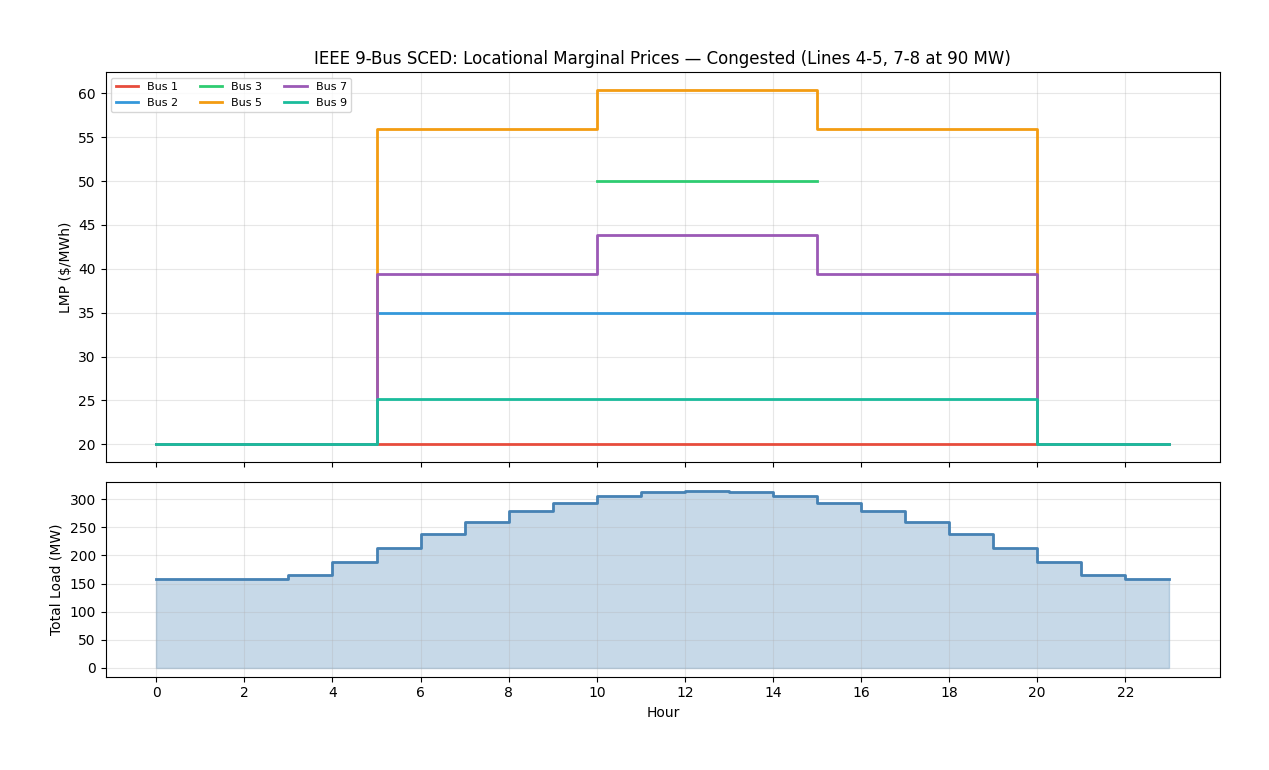

In [ ]:
all_buses = sorted(network.buses.index.tolist(), key=lambda x: int(x))

# Assign colors consistently
active_buses = sorted(lmp_pivot.columns.tolist(), key=lambda x: int(x))
palette_idx = 0
bus_color_map = {}
for b in all_buses:
    if b in active_buses:
        bus_color_map[b] = BUS_PALETTE[palette_idx % len(BUS_PALETTE)]
        palette_idx += 1
    else:
        bus_color_map[b] = TRANSIT_COLOR

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                                gridspec_kw={'height_ratios': [2, 1]})

# Top: LMP per bus
for bus in active_buses:
    if bus in lmp_pivot.columns:
        ax1.step(lmp_pivot.index, lmp_pivot[bus], where='post',
                 label=f'Bus {bus}', color=bus_color_map[bus], linewidth=2)

ax1.set_ylabel('LMP ($/MWh)')
ax1.set_title(f'IEEE 9-Bus SCED: Locational Marginal Prices — {scenario_name}')
ax1.legend(loc='upper left', fontsize=8, ncol=3)
ax1.grid(True, alpha=0.3)

# Bottom: total load profile
total_load = [sum(abs(o['volume']) for o in orderbook
                  if o['volume'] < 0 and o['start_time'].hour == h)
              for h in range(periods)]
ax2.fill_between(range(periods), total_load, alpha=0.3, step='post', color='steelblue')
ax2.step(range(periods), total_load, where='post', color='steelblue', linewidth=2)
ax2.set_ylabel('Total Load (MW)')
ax2.set_xlabel('Hour')
ax2.set_xticks(range(0, periods, 2))
ax2.grid(True, alpha=0.3)

plt.tight_layout()

## Generator Dispatch (Stacked Area)

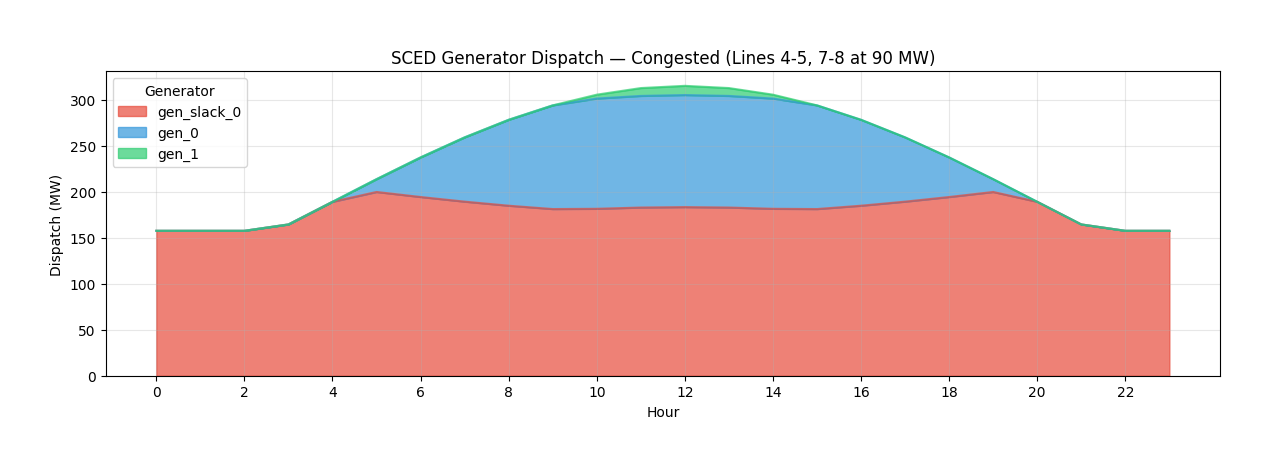

In [ ]:
# Build dispatch table from accepted supply orders
supply_acc = acc_df[acc_df['volume'] > 0].copy()
supply_acc['hour'] = supply_acc['start_time'].dt.hour

dispatch_pivot = supply_acc.pivot_table(
    index='hour', columns='unit_id', values='accepted_volume', fill_value=0
).sort_index()

# Order columns by marginal cost (cheapest at bottom), derived from config
gen_order = sorted(gen_data.keys(), key=lambda g: gen_data[g]['price'])
gen_colors = {g: bus_color_map.get(gen_data[g]['bus'], '#888') for g in gen_order}
cols = [c for c in gen_order if c in dispatch_pivot.columns]

fig, ax = plt.subplots(figsize=(12, 4))
dispatch_pivot[cols].plot.area(
    ax=ax, alpha=0.7,
    color=[gen_colors[c] for c in cols],
)
ax.set_ylabel('Dispatch (MW)')
ax.set_xlabel('Hour')
ax.set_title(f'SCED Generator Dispatch — {scenario_name}')
ax.legend(title='Generator', loc='upper left')
ax.set_xticks(range(0, periods, 2))
ax.grid(True, alpha=0.3)
plt.tight_layout()

## Nodal View — Hour Detail

Change `PLOT_HOUR` at the top to select a different hour. The circlize plot shows:
- **Left (GEN)**: merit order staircase — solid fill = dispatched, faded = available capacity
- **Right (LOAD)**: demand bar, height = bus LMP
- **Chords**: gen-to-load flows via PTDF decomposition (physically-based allocation)
- **Inner ring**: solid = net sender, outline = net receiver, thin = transit

Network topology shows dispatch/capacity for gens, served/requested for loads.

In [ ]:
def get_hour_data(hour_idx):
    """Extract supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps for a given hour."""
    t_start = market_products[hour_idx][0]

    # Supply: generators at this hour (from both accepted and rejected)
    supply_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] <= 0:
            continue
        bus = o['node']
        if bus not in supply_by_bus:
            supply_by_bus[bus] = []
        supply_by_bus[bus].append({
            'unit_id': o['unit_id'],
            'price': o['price'],
            'volume': o['volume'],
            'accepted_volume': o.get('accepted_volume', 0),
        })
    # Sort each bus by price (merit order)
    for bus in supply_by_bus:
        supply_by_bus[bus].sort(key=lambda g: g['price'])

    # Demand: requested load at this hour (from volume)
    demand_by_bus = {}
    demand_served_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] >= 0:
            continue
        bus = o['node']
        demand_by_bus[bus] = demand_by_bus.get(bus, 0) + abs(o['volume'])
        demand_served_by_bus[bus] = demand_served_by_bus.get(bus, 0) + abs(o.get('accepted_volume', 0))

    # LMPs: from accepted orders at this hour
    bus_lmps = {}
    for o in accepted:
        if o['start_time'] == t_start:
            bus_lmps[o['node']] = o['accepted_price']

    # Extract Egret solver line flows for this hour
    # flows dict is {(line_name, t_idx): flow_MW} — values are in MW (baseMVA-scaled)
    hour_line_flows = {}
    for (line_name, t_idx), flow_mw in flows.items():
        if t_idx == hour_idx:
            hour_line_flows[line_name] = flow_mw

    return supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows


def plot_hour(hour_idx):
    """Plot circlize + network topology for a given hour."""
    supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows = get_hour_data(hour_idx)
    t_start = market_products[hour_idx][0]

    colors = assign_bus_colors(all_buses, supply_by_bus, demand_by_bus)

    # PTDF-based gen-to-load flow allocation
    flow_list = compute_ptdf_flows(network, supply_by_bus, demand_by_bus)

    m = meta[hour_idx]
    avg_lmp = m['price']

    fig_circ = plot_nodal_circlize(
        supply_by_bus, demand_by_bus, all_buses,
        flows=flow_list,
        clearing_price=avg_lmp,
        bus_lmps=bus_lmps,
        title=f'{scenario_name} — Hour {hour_idx:02d} ({t_start.strftime("%Y-%m-%d %H:%M")})',
        bus_colors=colors,
    )

    # Use actual Egret solver line flows for the topology diagram
    fig_topo, ax_topo = plot_network_topology(
        network, supply_by_bus, demand_by_bus,
        bus_colors=colors,
        bus_lmps=bus_lmps,
        demand_served_by_bus=demand_served_by_bus,
        line_flows=hour_line_flows if hour_line_flows else None,
        title=f'{scenario_name} — Hour {hour_idx:02d} (Avg LMP: ${avg_lmp:.0f}/MWh)',
    )

    plt.show()

    # Print summary
    print(f'\nHour {hour_idx:02d} Summary ({scenario_name}):')
    print(f'  Total demand: {m["demand_volume"]:.1f} MW')
    print(f'  Total supply: {m["supply_volume"]:.1f} MW')
    print(f'  Avg LMP: ${avg_lmp:.2f}/MWh  (range: ${m["min_price"]:.2f} - ${m["max_price"]:.2f})')
    print(f'  Bus LMPs: {bus_lmps}')
    print(f'  Dispatch:')
    for bus, gens in sorted(supply_by_bus.items()):
        for g in gens:
            if g['accepted_volume'] > 0.1:
                print(f'    {g["unit_id"]} (bus {bus}): '
                      f'{g["accepted_volume"]:.1f}/{g["volume"]:.0f} MW @ ${g["price"]:.0f}')
    print(f'  Loads:')
    for bus in sorted(demand_by_bus.keys()):
        served = demand_served_by_bus.get(bus, 0)
        requested = demand_by_bus[bus]
        print(f'    bus {bus}: {served:.1f}/{requested:.1f} MW')
    print(f'  PTDF Gen-to-Load flows:')
    for src, dst, mw in sorted(flow_list, key=lambda x: (-x[2])):
        print(f'    Bus {src} -> Bus {dst}: {mw:.1f} MW')
    if hour_line_flows:
        print(f'  Solver line flows:')
        for ln, fl in sorted(hour_line_flows.items()):
            row = network.lines.loc[ln]
            direction = f"{row['bus0']}->{row['bus1']}" if fl >= 0 else f"{row['bus1']}->{row['bus0']}"
            constrained = '*' if abs(fl) >= 0.95 * row['s_nom'] else ''
            print(f'    {ln} ({direction}): {abs(fl):.1f}/{row["s_nom"]:.0f} MW {constrained}')

print('plot_hour() ready')

plot_hour() ready


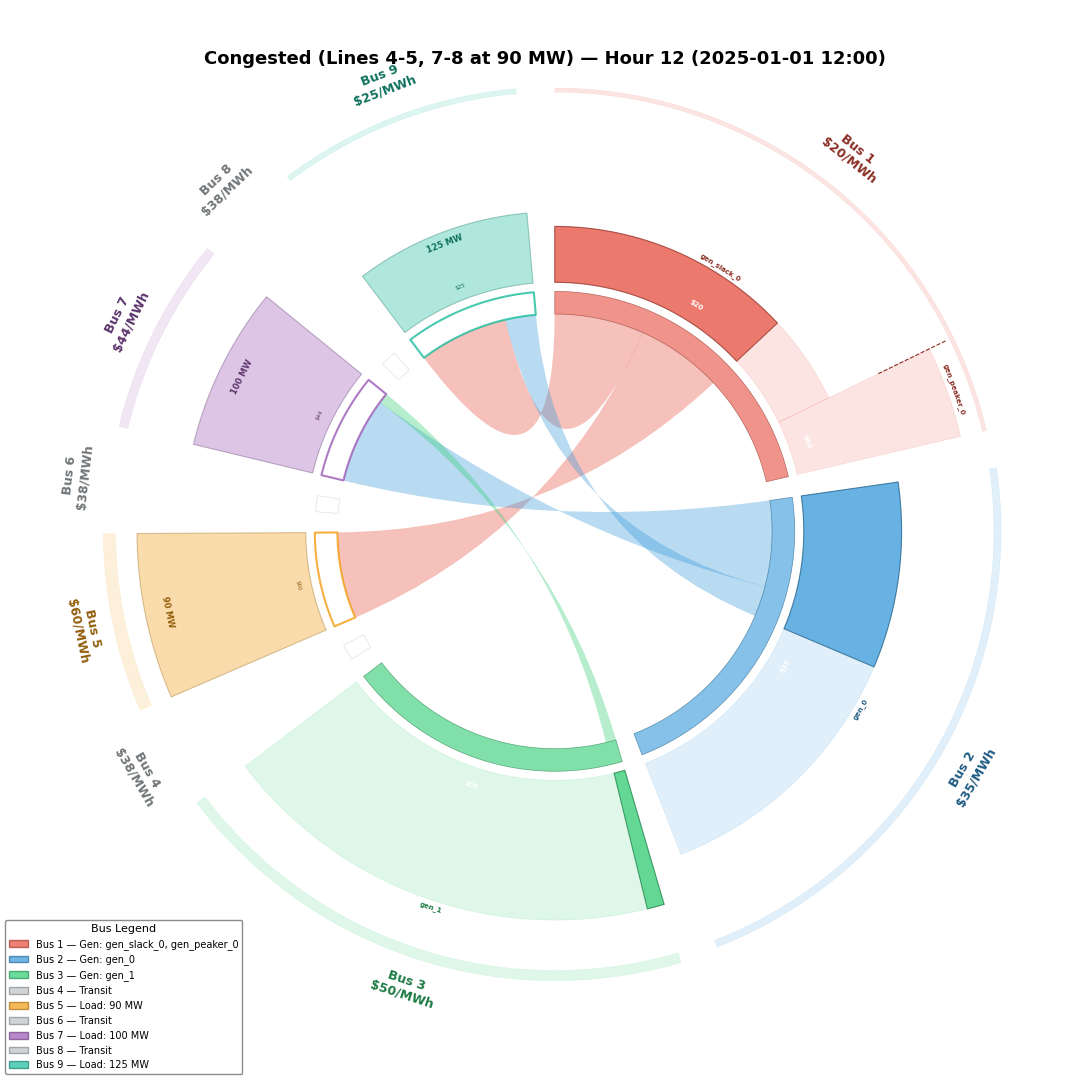

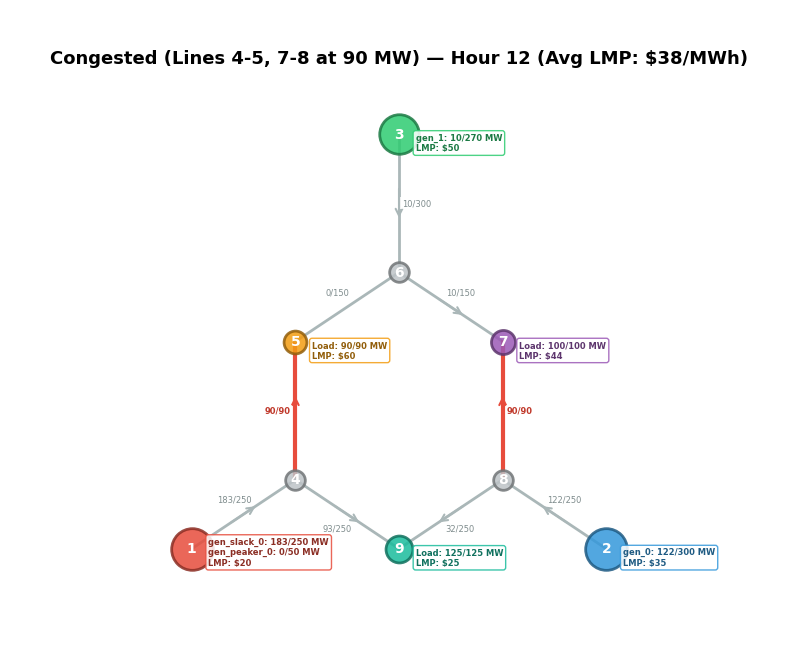


Hour 12 Summary (Congested (Lines 4-5, 7-8 at 90 MW)):
  Total demand: 315.0 MW
  Total supply: 315.0 MW
  Avg LMP: $37.71/MWh  (range: $20.00 - $60.37)
  Bus LMPs: {'1': 20.0, '2': 34.99999999999998, '3': 49.99999999999999, '5': 60.365853658536544, '7': 43.853658536585364, '9': 25.18292682926829}
  Dispatch:
    gen_slack_0 (bus 1): 183.2/250 MW @ $20
    gen_0 (bus 2): 121.8/300 MW @ $35
    gen_1 (bus 3): 10.0/270 MW @ $50
  Loads:
    bus 5: 90.0/90.0 MW
    bus 7: 100.0/100.0 MW
    bus 9: 125.0/125.0 MW
  PTDF Gen-to-Load flows:
    Bus 1 -> Bus 9: 93.2 MW
    Bus 1 -> Bus 5: 90.0 MW
    Bus 2 -> Bus 7: 89.5 MW
    Bus 2 -> Bus 9: 31.8 MW
    Bus 3 -> Bus 7: 10.5 MW
  Solver line flows:
    line_0 (1->4): 183.2/250 MW 
    line_1 (4->5): 90.0/90 MW *
    line_2 (6->5): 0.0/150 MW 
    line_3 (3->6): 10.0/300 MW 
    line_4 (6->7): 10.0/150 MW 
    line_5 (8->7): 90.0/90 MW *
    line_6 (2->8): 121.8/250 MW 
    line_7 (8->9): 31.8/250 MW 
    line_8 (4->9): 93.2/250 MW 


In [ ]:
plot_hour(PLOT_HOUR)

## Order Details Table

In [ ]:
# Show all accepted orders for the selected hour
t = market_products[PLOT_HOUR][0]
hour_acc = acc_df[acc_df['start_time'] == t].copy()

print(f'Hour {PLOT_HOUR} — Accepted Orders ({scenario_name}):')
hour_acc[['unit_id', 'node', 'price', 'volume', 'accepted_price', 'accepted_volume']].sort_values('price')

Hour 12 — Accepted Orders (Congested (Lines 4-5, 7-8 at 90 MW)):


,unit_id,node,price,volume,accepted_price,accepted_volume
12,gen_slack_0,1,20.0,250.0,20.000000,183.223577
31,gen_0,2,35.0,300.0,35.000000,121.776423
41,gen_1,3,50.0,270.0,50.000000,10.000000
56,load_0,5,1000.0,-90.0,60.365854,-90.000000
80,load_1,7,1000.0,-100.0,43.853659,-100.000000
104,load_2,9,1000.0,-125.0,25.182927,-125.000000


## Generator Economics

In [ ]:
# Revenue = LMP * dispatch, Cost = marginal_cost * dispatch
supply_acc = acc_df[acc_df['volume'] > 0].copy()
supply_acc['revenue'] = supply_acc['accepted_price'] * supply_acc['accepted_volume']
supply_acc['cost'] = supply_acc['price'] * supply_acc['accepted_volume']

econ = supply_acc.groupby('unit_id').agg(
    total_dispatch_MWh=('accepted_volume', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_cost=('cost', 'sum'),
).round(2)
econ['profit'] = econ['total_revenue'] - econ['total_cost']
econ['avg_lmp'] = (econ['total_revenue'] / econ['total_dispatch_MWh']).round(2)

print('Generator Economics (24h):')
econ

Generator Economics (24h):

,total_dispatch_MWh,total_revenue,total_cost,profit,avg_lmp
unit_id,,,,,
gen_0,1269.58,44435.18,44435.18,0.0,35.0
gen_1,35.51,1775.45,1775.45,0.0,50.0
gen_slack_0,4303.55,86071.02,86071.02,0.0,20.0
